# Add-on: evaluate only where there are actual rentals

Most station-hours have 0 or very few rentals, so a model that predicts "about nothing" already gets small errors. This add-on scores every model **again on the hours where actual rentals > 0**, next to the usual all-rows score.

**Use it two ways**
1. **Run this notebook** - it scores every `data/predictions/test_*` file in the repo (all your models + the baselines).
2. **Drop it into any model notebook** - copy the function cell (section 2) in and call  
   `score_all_vs_nonzero(y_test, {"my_model": y_pred})`.

Run `baseline_historical.ipynb` first (same Colab session or after pulling its saved files) if you want the baselines included.

## 1. Connect to GitHub and load the data

In [6]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/amelia-lee-smu/CS610-Applied-Machine-Learning.git"
BRANCH   = "main"     # README links the processed data on branch "feat/eda-for-proposal";
                      # if data/processed is missing on main, change this, delete the cloned folder, re-run
REPO_DIR = Path("CS610-Applied-Machine-Learning")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"])

print("Repo folders:", sorted(p.name for p in REPO_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")))

Repo folders: ['data', 'models', 'notebooks', 'references', 'utilities']


In [7]:
try:
    import pyarrow  # noqa
except ImportError:
    %pip install -q pyarrow

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

DATA_DIR = REPO_DIR / "data" / "processed"
PRED_DIR = REPO_DIR / "data" / "predictions"

files = sorted(p for p in DATA_DIR.rglob("*") if p.suffix in {".parquet", ".csv"}) if DATA_DIR.exists() else []
if not files:
    raise FileNotFoundError(f"No .parquet/.csv files in {DATA_DIR}. Try another BRANCH in the first cell.")

def read(p):
    return pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p)

for p in files:   # Git LFS pointer check
    if p.stat().st_size < 300 and b"git-lfs" in p.read_bytes():
        raise RuntimeError(f"{p.name} is a Git LFS pointer - run `git lfs pull` in the repo.")

raw = {p.name: read(p) for p in files}
for name, d in raw.items():
    print(f"{name}: {d.shape}")

test.parquet: (74409, 17)
train_validation.parquet: (520149, 17)


## 2. Identify columns and test set

In [9]:
OVERRIDE = dict(station=None, target="num_rentals", time=None, date=None, hour=None)   # e.g. dict(target="rental_count")

df_all = pd.concat(raw.values(), ignore_index=True)
cols = {c.lower(): c for c in df_all.columns}

def pick(override, candidates=(), predicate=None):
    if override: return override
    for c in candidates:
        if c in cols: return cols[c]
    if predicate:
        for lc, c in cols.items():
            if predicate(lc): return c
    return None

STATION = pick(OVERRIDE["station"], ["station", "station_name", "start_station_name", "start_station_id", "station_id"],
               lambda c: "station" in c and not any(k in c for k in ("lat", "lng", "lon")))
TARGET  = pick(OVERRIDE["target"], ["rentals", "rental", "rental_count", "rentals_count", "count", "demand", "n_rentals", "trips", "y"])
TIME    = pick(OVERRIDE["time"], ["datetime", "timestamp", "date_time", "time"],
               lambda c: pd.api.types.is_datetime64_any_dtype(df_all[cols[c]]))
DATE    = pick(OVERRIDE["date"], ["date"]) if TIME is None else None
HOUR    = pick(OVERRIDE["hour"], ["hour", "hour_of_day"]) if TIME is None else None

print(dict(STATION=STATION, TARGET=TARGET, TIME=TIME, DATE=DATE, HOUR=HOUR))
missing = [k for k, v in dict(station=STATION, target=TARGET).items() if v is None]
if missing or (TIME is None and (DATE is None or HOUR is None)):
    print("Columns available:", list(df_all.columns))
    raise ValueError(f"Could not detect {missing or 'time columns'} - set OVERRIDE above.")

if TIME is None:
    df_all["_ts"] = pd.to_datetime(df_all[DATE]) + pd.to_timedelta(df_all[HOUR], unit="h")
else:
    df_all["_ts"] = pd.to_datetime(df_all[TIME])

df_all = df_all.drop_duplicates([STATION, "_ts"]).sort_values([STATION, "_ts"]).reset_index(drop=True)
print(f"{df_all[STATION].nunique()} stations, {df_all['_ts'].min()} -> {df_all['_ts'].max()}, {len(df_all):,} rows")

TEST_START = pd.Timestamp("2021-03-01")          # test = 1 Mar - 30 Apr 2021 (as in the README)
test = df_all[df_all["_ts"] >= TEST_START].reset_index(drop=True)
KEYS = [STATION, "_ts"]
print(f"test rows: {len(test):,}")

{'STATION': 'start station name', 'TARGET': 'num_rentals', 'TIME': None, 'DATE': 'date', 'HOUR': 'hour_of_day'}
51 stations, 2020-01-01 00:00:00 -> 2021-04-30 19:00:00, 594,558 rows
test rows: 74,409


## 3. The add-on function (copy this cell into any model notebook)

In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

def score_all_vs_nonzero(y_true, preds, eps=1e-3):
    """Score one or more models on ALL rows and on rows where actual rentals > 0 only.

    y_true : actual rentals (array/Series)
    preds  : dict {model_name: predictions}  (same length/order as y_true)
    Returns a DataFrame indexed by (subset, model) with MAE, RMSE, Poisson deviance and n.
    Predictions are clipped at `eps` because Poisson deviance needs predictions > 0.
    """
    y = np.asarray(y_true, float)
    rows = []
    for subset, mask in {"all rows": np.ones(len(y), bool), "actual > 0 only": y > 0}.items():
        for name, p in preds.items():
            p = np.clip(np.asarray(p, float)[mask], eps, None)
            rows.append({"subset": subset, "model": name,
                         "MAE": mean_absolute_error(y[mask], p),
                         "RMSE": mean_squared_error(y[mask], p) ** 0.5,
                         "Poisson dev": mean_poisson_deviance(y[mask], p),
                         "n": int(mask.sum())})
    return pd.DataFrame(rows).set_index(["subset", "model"])

## 4. Score every saved model
Prediction files are matched to the test set by row order (if the row count matches) or by station + time columns.

In [11]:
preds, skipped = {}, []
for f in sorted(PRED_DIR.glob("test_*")) if PRED_DIR.exists() else []:
    name = f.stem.removeprefix("test_")
    p = read(f)
    num = [c for c in p.columns if pd.api.types.is_numeric_dtype(p[c])]
    pc = next((c for c in ("prediction", "pred", "y_pred", "predicted", name) if c in p.columns), None) or (num[-1] if num else None)
    if pc is None:
        skipped.append((f.name, "no numeric prediction column")); continue
    if STATION in p.columns and ("_ts" in p.columns or TIME in p.columns):
        p["_ts"] = pd.to_datetime(p["_ts"] if "_ts" in p.columns else p[TIME])
        m = test[KEYS + [TARGET]].merge(p[KEYS + [pc]], on=KEYS, how="left")
        preds[name] = m[pc]
    elif len(p) == len(test):
        preds[name] = p[pc].to_numpy()
    else:
        skipped.append((f.name, f"{len(p)} rows, expected {len(test)}"))

for s in skipped: print("skipped", *s)
if not preds:
    raise RuntimeError(f"No usable prediction files in {PRED_DIR}.")

# rows where every model has a prediction (baselines lose the first weeks of history only)
P = pd.DataFrame(preds); ok = P.notna().all(axis=1).to_numpy()
y = test[TARGET].to_numpy()
print(f"zero-rental share of test hours: {(y == 0).mean():.1%}   |   models: {list(preds)}")
res = score_all_vs_nonzero(y[ok], {k: v.to_numpy()[ok] for k, v in P.items()})
res.round(3)

zero-rental share of test hours: 71.6%   |   models: ['ensemble', 'lightgbm', 'neural_network', 'poisson_regression', 'random_forest']


MAE   RMSE  Poisson dev      n
subset          model                                               
all rows        ensemble            0.503  0.949        0.940  74409
                lightgbm            0.510  0.986        1.009  74409
                neural_network      0.511  0.972        0.973  74409
                poisson_regression  0.537  0.962        0.933  74409
                random_forest       0.558  0.995        1.052  74409
actual > 0 only ensemble            1.167  1.660        2.106  21148
                lightgbm            1.226  1.737        2.414  21148
                neural_network      1.193  1.679        2.216  21148
                poisson_regression  1.081  1.623        1.665  21148
                random_forest       1.144  1.651        2.066  21148

## 5. Compare

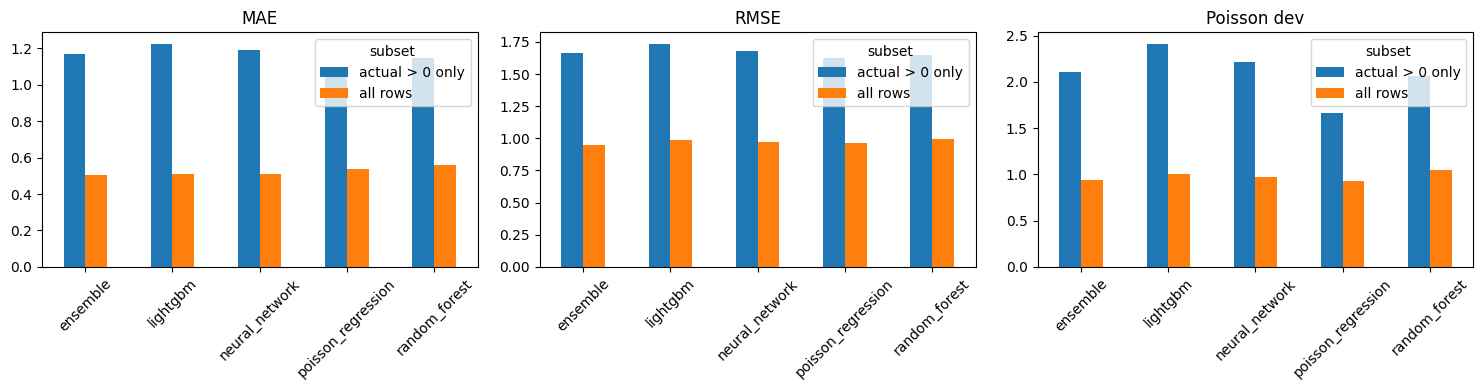

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ["MAE", "RMSE", "Poisson dev"]):
    res[m].unstack("subset").plot.bar(ax=ax, rot=45, title=m); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Reading the results:** the "actual > 0 only" numbers are the harder, more honest test of *how well the model sizes real demand*. They don't penalise predicting demand when none occurs, so keep the all-rows scores alongside them in your report.